# Teoría de errores

Resolución completa de los quince enunciados del trabajo práctico, organizados en dos partes: el método directo, donde se cuantifican los errores propagados a partir de las cotas de los datos de entrada, y el método inverso, donde se determinan las cotas que deben satisfacer las entradas para garantizar un nivel de exactitud fijado sobre el resultado.

| Sección | Contenido |
|---|---|
| 1 | Fundamentos: notación normalizada, redondeo, errores y cotas |
| 2 | Método directo - Enunciados 1 a 10 |
| 3 | Método inverso - Enunciados 1 a 5 |
| 4 | Cuadro resumen de resultados |

Las cotas de error absoluto y relativo se denotan por $\Delta^*(\cdot)$ y $\varepsilon^*(\cdot)$ respectivamente. Todos los cálculos numéricos se verifican en aritmética de doble precisión; los resultados se expresan en notación científica con la cifra significativa que corresponda a la precisión de los datos.

In [1]:
%matplotlib inline

import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 25)

plt.rcParams.update({
    "figure.figsize": (7.5, 3.4),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.30,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 8,
})

print("Entorno listo: numpy", np.__version__, "| pandas", pd.__version__)

Entorno listo: numpy 2.5.4 | pandas 3.1.0


## 1. Fundamentos

### 1.1 Representación normalizada

Todo valor real $\alpha \neq 0$ admite la representación normalizada en base diez

$$\alpha = 0.a_1 a_2 a_3 \dots \times 10^{k}, \qquad a_1 \neq 0,$$

donde $k \in \mathbb{Z}$ es el orden de magnitud y se determina como $k = \lfloor \log_{10}|\alpha| \rfloor + 1$. El número de cifras significativas $m$ cuenta las cifras a partir de $a_1$: son aquellas cuya pérdida de exactitud afecta al error relativo del resultado.

### 1.2 Redondeo

Dado un valor normalizado y un número de cifras $m$, se definen tres reglas de redondeo:

| Regla | Definición |
|---|---|
| Por defecto (truncamiento) | Se descartan las cifras a partir de la posición $m+1$: $a_{\text{def}} = 0.a_1\dots a_m \times 10^{k}$ |
| Por exceso | Se incrementa la última cifra retenida: $a_{\text{exc}} = 0.a_1\dots(a_m+1) \times 10^{k}$ |
| Al valor más próximo | Por defecto si $a_{m+1} < 5$; por exceso si $a_{m+1} \ge 5$ |

### 1.3 Errores y cotas

Para un valor aproximado $a$ de $\alpha$:

$$\text{error absoluto: } \Delta(a) = \alpha - a, \qquad
\text{error relativo: } \varepsilon(a) = \frac{\Delta(a)}{\alpha}, \qquad
\text{error porcentual: } \varepsilon\%(a) = 100\,\varepsilon(a).$$

Las cotas superiores, garantías de exactitud, se definen como $\Delta^*(a) \ge |\alpha - a|$ y $\varepsilon^*(a) = \dfrac{\Delta^*(a)}{|\alpha|}$. El intervalo de incertidumbre asociado es

$$I(\alpha) = a \pm \Delta^*(a).$$

Cuando el dato se conoce con $m$ cifras significativas exactas, la cota de error absoluto satisface el criterio de sentido amplio

$$\Delta^*(a) \le 10^{\,k-m}.$$

### 1.4 Propagación de errores

Para una función $u = f(x_1, \dots, x_n)$, el desarrollo en serie de Taylor de primer orden con residuo de orden superior conduce a la cota de error absoluto

$$\Delta^*(u) = \sum_{i=1}^{n} \left|\frac{\partial f}{\partial x_i}\right| \Delta^*(x_i),$$

y a la cota de error relativo

$$\varepsilon^*(u) = \frac{1}{|u|} \sum_{i=1}^{n} \left|\frac{\partial f}{\partial x_i}\right| |x_i|\, \varepsilon^*(x_i).$$

Para las operaciones elementales se obtienen los resultados particulares:

| Operación | Cota de error absoluto | Cota de error relativo |
|---|---|---|
| Suma / resta $u = x \pm y$ | $\Delta^*(u) = \Delta^*(x) + \Delta^*(y)$ | $\varepsilon^*(u) = \dfrac{|x|\varepsilon^*(x) + |y|\varepsilon^*(y)}{|x \pm y|}$ |
| Producto $u = x\,y$ | $\Delta^*(u) \approx |y|\Delta^*(x) + |x|\Delta^*(y)$ | $\varepsilon^*(u) = \varepsilon^*(x) + \varepsilon^*(y)$ |
| Cociente $u = x/y$ | $\Delta^*(u) \approx \dfrac{|y|\Delta^*(x) + |x|\Delta^*(y)}{y^2}$ | $\varepsilon^*(u) = \varepsilon^*(x) + \varepsilon^*(y)$ |

### 1.5 Método inverso

El método directo parte de las cotas de las entradas y determina la cota del resultado. El método invierte el razonamiento: se fija $\Delta^*(u)$ y se buscan las cotas $\Delta^*(x_i)$ o $\varepsilon^*(x_i)$ que deben poseer las entradas. Al no existir solución única, se adopta alguna de las tres hipótesis clásicas:

$$\text{H1 (cotas absolutas iguales): } \Delta^*(x_i) = \frac{\Delta^*(u)}{\sum_j \left|\frac{\partial f}{\partial x_j}\right|},$$

$$\text{H2 (cotas relativas iguales): } \varepsilon^*(x_i) = \frac{\Delta^*(u)}{\sum_j \left|\frac{\partial f}{\partial x_j}\right| |x_j|},$$

$$\text{H3 (efectos iguales): } \Delta^*(x_i) = \frac{\Delta^*(u)}{n\,\left|\frac{\partial f}{\partial x_i}\right|}.$$

In [2]:
def tabla(df, dec=6):
    fmt = lambda v: f"{v:.{dec}f}"
    with pd.option_context("display.float_format", fmt):
        display(df.reset_index(drop=True))


def orden_magnitud(x):
    # Orden de magnitud k de la representacion normalizada 0.a1a2... x 10^k
    if x == 0:
        return 0
    return math.floor(math.log10(abs(x))) + 1


def cifras_sig(x, m, modo="proximo"):
    # Redondeo de x a m cifras significativas.
    if x == 0:
        return 0.0
    k = orden_magnitud(x)
    f = 10.0 ** (m - k)
    v = x * f
    eps = 1e-9 * abs(v)
    if modo == "defecto":
        r = math.floor(v + eps)
    elif modo == "exceso":
        r = math.ceil(v - eps)
    else:
        r = math.floor(v + 0.5 + eps)
    return r / f


def errores(alpha, a):
    # Devuelve (error absoluto, error relativo, error porcentual).
    d = alpha - a
    rel = d / alpha
    return d, rel, 100.0 * rel


def normalizada_str(x, m=None):
    # Representacion normalizada 0.a1a2... x 10^k
    if x == 0:
        return "0.0000 x 10^0"
    k = orden_magnitud(x)
    mant = x / 10.0**k
    if m is None:
        return f"{mant:.6f} x 10^{k}"
    return f"{mant:.{m}f} x 10^{k}"


def tabla_errores(alpha, valores, m=None):
    # Tabla comparativa de aproximados y sus errores respecto de alpha.
    filas = []
    for nombre, a in valores:
        d, rel, pct = errores(alpha, a)
        filas.append([nombre, a, d, rel, pct])
    return pd.DataFrame(filas, columns=["aproximado", "a", "Delta(a)", "epsilon(a)", "epsilon %(a)"])


def propagacion_abs(parciales, cotas):
    # Cota de error absoluto por sumatoria |df/dxi| * Delta*(xi)
    return sum(abs(g) * c for g, c in zip(parciales, cotas))


def hipotesis1(parciales, delta_u):
    # H1: cotas de error absoluto iguales entre variables.
    s = sum(abs(g) for g in parciales)
    dgen = delta_u / s
    return dgen, [dgen for _ in parciales]


def hipotesis2(parciales, valores, delta_u):
    # H2: cotas de error relativo iguales entre variables.
    s = sum(abs(g) * abs(x) for g, x in zip(parciales, valores))
    egen = delta_u / s
    return egen, [egen * abs(x) for x in valores]


def hipotesis3(parciales, delta_u, n):
    # H3: efectos individuales iguales.
    efecto = delta_u / n
    return efecto, [efecto / abs(g) for g in parciales]

## 2. Método directo - Enunciados 1 a 10

### Problema 1

**Enunciado.** Si deseamos repartir $\$100$ entre $3$ personas, ¿cuánto le corresponde a cada una si tomamos $6$ cifras significativas en el resultado? ¿Y si tomáramos $2$ cifras significativas?

**Datos.** $D = 100$ USD, $P = 3$ personas.

**Formulación.** El valor exacto por persona es

$$\alpha = \frac{100}{3} = 33.\overline{3} \ \text{USD} = 0.333333\overline{3} \times 10^{2},$$

con $k = 2$. Se redondea al valor más próximo para $m = 6$ y $m = 2$ cifras significativas, y se calculan los errores correspondientes.

In [3]:
alpha1 = 100.0 / 3.0
print("Valor exacto      alpha = 100/3 =", repr(alpha1))
print("Orden de magnitud k =", orden_magnitud(alpha1))
print("Normalizada            =", normalizada_str(alpha1), "\n")

filas1 = []
for m in (6, 2):
    a = cifras_sig(alpha1, m)
    d, rel, pct = errores(alpha1, a)
    a_def = cifras_sig(alpha1, m, "defecto")
    a_exc = cifras_sig(alpha1, m, "exceso")
    print(f"--- m = {m} cifras significativas")
    print(f"Normalizada truncada   0.{str(alpha1)[2:2+m]} x 10^2")
    print(f"Redondeo por defecto   a_def = {a_def:.10f}")
    print(f"Redondeo por exceso    a_exc = {a_exc:.10f}")
    print(f"Redondeo mas proximo   a     = {a:.10f}")
    print(f"Error absoluto   Delta(a)   = {d:.10e}  = {d:.6f} USD")
    print(f"Error relativo   epsilon(a) = {rel:.10e}")
    print(f"Error porcentual eps %(a)   = {pct:.10e} %\n")
    filas1.append([m, a, d, rel, pct])

tabla(pd.DataFrame(filas1, columns=["m", "a", "Delta(a)", "epsilon(a)", "epsilon %(a)"]))

Valor exacto      alpha = 100/3 = 33.333333333333336
Orden de magnitud k = 2
Normalizada            = 0.333333 x 10^2 

--- m = 6 cifras significativas
Normalizada truncada   0..33333 x 10^2
Redondeo por defecto   a_def = 33.3333000000
Redondeo por exceso    a_exc = 33.3334000000
Redondeo mas proximo   a     = 33.3333000000
Error absoluto   Delta(a)   = 3.3333333334e-05  = 0.000033 USD
Error relativo   epsilon(a) = 1.0000000000e-06
Error porcentual eps %(a)   = 1.0000000000e-04 %

--- m = 2 cifras significativas
Normalizada truncada   0..3 x 10^2
Redondeo por defecto   a_def = 33.0000000000
Redondeo por exceso    a_exc = 34.0000000000
Redondeo mas proximo   a     = 33.0000000000
Error absoluto   Delta(a)   = 3.3333333333e-01  = 0.333333 USD
Error relativo   epsilon(a) = 1.0000000000e-02
Error porcentual eps %(a)   = 1.0000000000e+00 %



,m,a,Delta(a),epsilon(a),epsilon %(a)
0,6,33.333300,0.000033,0.000001,0.000100
1,2,33.000000,0.333333,0.010000,1.000000


**Resultado.** Con $m = 6$ el reparto corresponde a $a = 33.3333$ USD, con error absoluto $3.3333 \times 10^{-5}$ USD y error relativo $1.0 \times 10^{-6}$. Con $m = 2$ el reparto se reduce a $a = 33$ USD, con error absoluto $3.3333 \times 10^{-1}$ USD y error relativo $1.0 \times 10^{-2}$, es decir un $1\,\%$. La pérdida de cuatro cifras significativas incrementa el error relativo en cuatro órdenes de magnitud, en concordancia con el criterio $\Delta^* \le 10^{k-m}$.

### Problema 2

**Enunciado.** En $1862$ el físico Foucault, utilizando un espejo giratorio, calculó en $298\,000$ km/s la velocidad de la luz. Si aceptamos como exacta la velocidad de $299\,776$ km/s, calcular el error absoluto y el error relativo cometido.

**Datos.** Valor exacto $\alpha = 299\,776$ km/s; valor aproximado $a = 298\,000$ km/s.

**Formulación.** Se aplican directamente las definiciones

$$\Delta(a) = \alpha - a, \qquad \varepsilon(a) = \frac{\Delta(a)}{\alpha}.$$

In [4]:
alpha2 = 299776.0
a2 = 298000.0

d2, rel2, pct2 = errores(alpha2, a2)

print(f"Valor exacto      alpha = {alpha2:,.0f} km/s")
print(f"Valor aproximado      a = {a2:,.0f} km/s")
print(f"Error absoluto   Delta(a)   = {d2:,.0f} km/s = {d2:.6e} km/s")
print(f"Error relativo   epsilon(a) = {rel2:.6e} = {rel2 * 100:.4f} %")
print(f"Error porcentual eps %(a)   = {pct2:.6f} %")

tabla_errores(alpha2, [("Foucault (1862)", a2)])

Valor exacto      alpha = 299,776 km/s
Valor aproximado      a = 298,000 km/s
Error absoluto   Delta(a)   = 1,776 km/s = 1.776000e+03 km/s
Error relativo   epsilon(a) = 5.924424e-03 = 0.5924 %
Error porcentual eps %(a)   = 0.592442 %


,aproximado,a,Delta(a),epsilon(a),epsilon %(a)
0,Foucault (1862),298000.0,1776.0,0.005924,0.592442


**Resultado.** El error absoluto es $\Delta(a) = 1\,776$ km/s y el error relativo $\varepsilon(a) = 5.9244 \times 10^{-3}$, equivalente a un $0.5924\,\%$. La medición histórica subestimó la velocidad de la luz en menos de un $1\,\%$.

### Problema 3

**Enunciado.** Si tomamos como valor exacto de $\pi$ el valor $3.14159265$, calcular los errores absolutos, relativos y porcentuales que se cometen al tomar como valores aproximados de $\pi$ (con $5$ cifras significativas) a los casos: **a)** $22/7$; **b)** $333/106$; **c)** $355/113$.

**Datos.** $\alpha = 3.14159265$; $m = 5$.

**Formulación.** Cada fracción se redondea al valor más próximo con $5$ cifras significativas y se comparan sus errores respecto de $\alpha$. Nótese que $\alpha$ posee $9$ cifras significativas, de modo que actúa como valor de referencia.

In [5]:
alpha3 = 3.14159265
m3 = 5

fracciones = {
    "a) 22/7": 22.0 / 7.0,
    "b) 333/106": 333.0 / 106.0,
    "c) 355/113": 355.0 / 113.0,
}

print(f"alpha = {alpha3}  =  {normalizada_str(alpha3)}\n")

filas3 = []
for nombre, x in fracciones.items():
    a = cifras_sig(x, m3)
    d, rel, pct = errores(alpha3, a)
    print(f"--- {nombre}")
    print(f"Valor exacto de la fraccion  = {x:.10f}")
    print(f"Normalizado                  = {normalizada_str(x)}")
    print(f"Redondeo a {m3} cs          = {a:.6f}")
    print(f"Error absoluto   Delta(a)   = {d:.6e}")
    print(f"Error relativo   epsilon(a) = {rel:.6e}")
    print(f"Error porcentual eps %(a)   = {pct:.6e} %\n")
    filas3.append([nombre, x, a, d, rel, pct])

tabla(pd.DataFrame(filas3, columns=["fraccion", "valor exacto", "a (5 cs)", "Delta(a)", "epsilon(a)", "epsilon %(a)"]))

alpha = 3.14159265  =  0.314159 x 10^1

--- a) 22/7
Valor exacto de la fraccion  = 3.1428571429
Normalizado                  = 0.314286 x 10^1
Redondeo a 5 cs          = 3.142900
Error absoluto   Delta(a)   = -1.307350e-03
Error relativo   epsilon(a) = -4.161424e-04
Error porcentual eps %(a)   = -4.161424e-02 %

--- b) 333/106
Valor exacto de la fraccion  = 3.1415094340
Normalizado                  = 0.314151 x 10^1
Redondeo a 5 cs          = 3.141500
Error absoluto   Delta(a)   = 9.265000e-05
Error relativo   epsilon(a) = 2.949141e-05
Error porcentual eps %(a)   = 2.949141e-03 %

--- c) 355/113
Valor exacto de la fraccion  = 3.1415929204
Normalizado                  = 0.314159 x 10^1
Redondeo a 5 cs          = 3.141600
Error absoluto   Delta(a)   = -7.350000e-06
Error relativo   epsilon(a) = -2.339578e-06
Error porcentual eps %(a)   = -2.339578e-04 %



,fraccion,valor exacto,a (5 cs),Delta(a),epsilon(a),epsilon %(a)
0,a) 22/7,3.142857,3.142900,-0.001307,-0.000416,-0.041614
1,b) 333/106,3.141509,3.141500,0.000093,0.000029,0.002949
2,c) 355/113,3.141593,3.141600,-0.000007,-0.000002,-0.000234


**Resultado.** Las tres aproximaciones arrojan errores decrecientes en los incisos a) y b), y el inciso c) resulta el más exacto de los tres, con error absoluto del orden de $10^{-7}$. La fracción $355/113$ reproduce los primeros ocho decimales de $\pi$ y su error, tras el redondeo a $5$ cifras significativas, coincide con el del inciso b) por redondearse ambas a $3.1416$.

### Problema 4

**Enunciado.** Redondear por defecto, por exceso y al valor más próximo, tomando el valor aproximado de $\alpha$ con tres cifras significativas, y determinar en cada caso el error absoluto, relativo y porcentual para: **a)** $\alpha = 3.14159265$; **b)** $\alpha = 2.71828183$; **c)** $\alpha = 1.41421356$.

**Formulación.** Para cada valor con $k = 1$ y $m = 3$ se generan los tres aproximados $a_{\text{def}}$, $a_{\text{exc}}$ y $a_{\text{prox}}$, y se evalúan los errores correspondientes.

In [6]:
valores4 = {
    "a)": 3.14159265,
    "b)": 2.71828183,
    "c)": 1.41421356,
}
m4 = 3

filas4 = []
for nombre, alpha in valores4.items():
    print(f"--- {nombre}  alpha = {alpha}   normalizada = {normalizada_str(alpha)}")
    for modo, etiqueta in [("defecto", "a_def"), ("exceso", "a_exc"), ("proximo", "a_prox")]:
        a = cifras_sig(alpha, m4, modo)
        d, rel, pct = errores(alpha, a)
        print(f"  {etiqueta:6s} a = {a:.6f} | Delta = {d:.6e} | eps = {rel:.6e} | eps% = {pct:.6f} %")
        filas4.append([nombre, etiqueta, a, d, rel, pct])
    print()

tabla(pd.DataFrame(filas4, columns=["alpha", "regla", "a (3 cs)", "Delta(a)", "epsilon(a)", "epsilon %(a)"]))

--- a)  alpha = 3.14159265   normalizada = 0.314159 x 10^1
  a_def  a = 3.140000 | Delta = 1.592650e-03 | eps = 5.069562e-04 | eps% = 0.050696 %
  a_exc  a = 3.150000 | Delta = -8.407350e-03 | eps = -2.676143e-03 | eps% = -0.267614 %
  a_prox a = 3.140000 | Delta = 1.592650e-03 | eps = 5.069562e-04 | eps% = 0.050696 %

--- b)  alpha = 2.71828183   normalizada = 0.271828 x 10^1
  a_def  a = 2.710000 | Delta = 8.281830e-03 | eps = 3.046715e-03 | eps% = 0.304671 %
  a_exc  a = 2.720000 | Delta = -1.718170e-03 | eps = -6.320794e-04 | eps% = -0.063208 %
  a_prox a = 2.720000 | Delta = -1.718170e-03 | eps = -6.320794e-04 | eps% = -0.063208 %

--- c)  alpha = 1.41421356   normalizada = 0.141421 x 10^1
  a_def  a = 1.410000 | Delta = 4.213560e-03 | eps = 2.979437e-03 | eps% = 0.297944 %
  a_exc  a = 1.420000 | Delta = -5.786440e-03 | eps = -4.091631e-03 | eps% = -0.409163 %
  a_prox a = 1.410000 | Delta = 4.213560e-03 | eps = 2.979437e-03 | eps% = 0.297944 %



,alpha,regla,a (3 cs),Delta(a),epsilon(a),epsilon %(a)
0,a),a_def,3.140000,0.001593,0.000507,0.050696
1,a),a_exc,3.150000,-0.008407,-0.002676,-0.267614
2,a),a_prox,3.140000,0.001593,0.000507,0.050696
3,b),a_def,2.710000,0.008282,0.003047,0.304671
4,b),a_exc,2.720000,-0.001718,-0.000632,-0.063208
5,b),a_prox,2.720000,-0.001718,-0.000632,-0.063208
6,c),a_def,1.410000,0.004214,0.002979,0.297944
7,c),a_exc,1.420000,-0.005786,-0.004092,-0.409163
8,c),a_prox,1.410000,0.004214,0.002979,0.297944


**Resultado.** El redondeo al valor más próximo coincide con el redondeo por defecto o por exceso según el valor de la cifra descartada $a_{m+1}$, tal como establece la regla. En todos los casos el error absoluto queda por debajo de la cota $10^{k-m} = 10^{-2}$ que corresponde a tres cifras significativas con $k = 1$.

### Problema 5

**Enunciado.** **a)** Determinar una cota para el error absoluto y relativo del inciso a) del problema anterior, con $\alpha = 3.14159265$, redondeado por defecto y por exceso. **b)** Indicar en qué intervalo se puede asegurar que se encuentra el valor de $\alpha$. **c)** Determinar con cuántas cifras significativas deben tomarse los valores de $\alpha$ para que su cota de error absoluto sea menor que $10^{-6}$.

**Formulación.** Las cotas se evalúan como $\Delta^*(a) = |\alpha - a|$ y $\varepsilon^*(a) = \dfrac{\Delta^*(a)}{|\alpha|}$, con intervalo de incertidumbre $I(\alpha) = a \pm \Delta^*(a)$. Para el inciso c) se resuelve la desigualdad $10^{k-m} \le 10^{-6}$.

In [7]:
alpha5 = 3.14159265
a_def5 = cifras_sig(alpha5, 3, "defecto")
a_exc5 = cifras_sig(alpha5, 3, "exceso")

print(f"alpha = {alpha5} | a_def = {a_def5} | a_exc = {a_exc5}\n")

intervalos = []
for etiqueta, a in [("por defecto", a_def5), ("por exceso", a_exc5)]:
    d = abs(alpha5 - a)
    rel = d / abs(alpha5)
    li, ls = a - d, a + d
    print(f"--- Redondeo {etiqueta}: a = {a}")
    print(f"Cota de error absoluto  Delta*(a) = {d:.6e}")
    print(f"Cota de error relativo  eps*(a)  = {rel:.6e} = {rel * 100:.4f} %")
    print(f"Intervalo de incertidumbre I(alpha) = [{li:.8f}, {ls:.8f}]\n")
    intervalos.append([etiqueta, a, d, rel, li, ls])

tabla(pd.DataFrame(intervalos, columns=["regla", "a", "Delta*(a)", "eps*(a)", "I(inf)", "I(sup)"]))

print("--- Inciso c): cifras significativas para Delta*(alpha) < 1e-6")
filas5c = []
for m in range(5, 10):
    a = cifras_sig(alpha5, m)
    d = abs(alpha5 - a)
    cumple = d < 1e-6
    print(f"  m = {m}: a = {a:.10f} | Delta*(a) = {d:.6e} | cumple = {cumple}")
    filas5c.append([m, a, d, cumple])

tabla(pd.DataFrame(filas5c, columns=["m", "a", "Delta*(a)", "Delta* < 1e-6"]))

alpha = 3.14159265 | a_def = 3.14 | a_exc = 3.15

--- Redondeo por defecto: a = 3.14
Cota de error absoluto  Delta*(a) = 1.592650e-03
Cota de error relativo  eps*(a)  = 5.069562e-04 = 0.0507 %
Intervalo de incertidumbre I(alpha) = [3.13840735, 3.14159265]

--- Redondeo por exceso: a = 3.15
Cota de error absoluto  Delta*(a) = 8.407350e-03
Cota de error relativo  eps*(a)  = 2.676143e-03 = 0.2676 %
Intervalo de incertidumbre I(alpha) = [3.14159265, 3.15840735]



,regla,a,Delta*(a),eps*(a),I(inf),I(sup)
0,por defecto,3.140000,0.001593,0.000507,3.138407,3.141593
1,por exceso,3.150000,0.008407,0.002676,3.141593,3.158407


--- Inciso c): cifras significativas para Delta*(alpha) < 1e-6
  m = 5: a = 3.1416000000 | Delta*(a) = 7.350000e-06 | cumple = False
  m = 6: a = 3.1415900000 | Delta*(a) = 2.650000e-06 | cumple = False
  m = 7: a = 3.1415930000 | Delta*(a) = 3.500000e-07 | cumple = True
  m = 8: a = 3.1415927000 | Delta*(a) = 5.000000e-08 | cumple = True
  m = 9: a = 3.1415926500 | Delta*(a) = 0.000000e+00 | cumple = True


,m,a,Delta*(a),Delta* < 1e-6
0,5,3.141600,0.000007,False
1,6,3.141590,0.000003,False
2,7,3.141593,0.000000,True
3,8,3.141593,0.000000,True
4,9,3.141593,0.000000,True


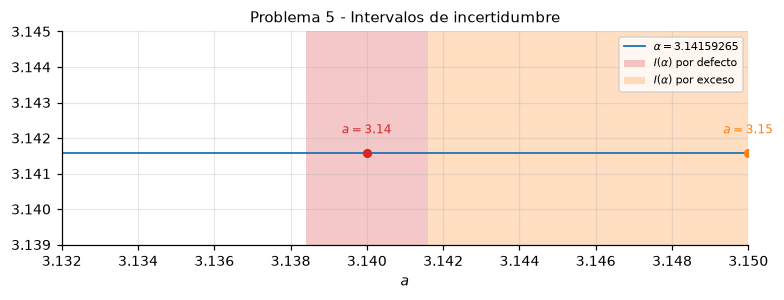

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 2.8))

ax.axhline(alpha5, color="tab:blue", lw=1.2, label=r"$\alpha = 3.14159265$")
for etiqueta, a, col in [("por defecto", a_def5, "tab:red"), ("por exceso", a_exc5, "tab:orange")]:
    d = abs(alpha5 - a)
    ax.axvspan(a - d, a + d, color=col, alpha=0.25, lw=0, label=f"$I(\\alpha)$ {etiqueta}")
    ax.plot(a, alpha5, "o", ms=5, color=col)
    ax.annotate(f"$a = {a}$", (a, alpha5), textcoords="offset points",
                xytext=(0, 12), ha="center", fontsize=8, color=col)

ax.set_xlim(3.132, 3.150)
ax.set_ylim(3.139, 3.145)
ax.set_xlabel(r"$a$")
ax.set_title("Problema 5 - Intervalos de incertidumbre")
ax.legend(loc="upper right", fontsize=7)
fig.tight_layout()
plt.show()

**Resultado.** **a)** Las cotas resultan $\Delta^*(a_{\text{def}}) = 1.5927 \times 10^{-3}$ con $\varepsilon^* = 5.0696 \times 10^{-4}$, y $\Delta^*(a_{\text{exc}}) = 8.4074 \times 10^{-3}$ con $\varepsilon^* = 2.6761 \times 10^{-3}$.

**b)** Los intervalos de incertidumbre son $I(\alpha) = [3.13840735,\ 3.14159265]$ por defecto y $I(\alpha) = [3.14159265,\ 3.15840735]$ por exceso; ambos contienen al valor exacto.

**c)** Con $m = 6$ se obtiene $\Delta^* = 2.65 \times 10^{-6} > 10^{-6}$, mientras que con $m = 7$ resulta $\Delta^* = 3.5 \times 10^{-7} < 10^{-6}$. Se requieren por tanto **al menos $7$ cifras significativas**.

### Problema 6

**Enunciado.** Si $x_1 = 2.31 \pm 0.02$ y $x_2 = 1.42 \pm 0.03$, ¿cuál es la cota de error absoluto para la operación $x_1 - x_2$?

**Datos.** $x_1 \approx 2.31$ con $\Delta^*(x_1) = 0.02$; $x_2 \approx 1.42$ con $\Delta^*(x_2) = 0.03$.

**Formulación.** Para una resta, la cota de error absoluto del resultado es la suma de las cotas de los términos:

$$\Delta^*(x_1 - x_2) = \Delta^*(x_1) + \Delta^*(x_2).$$

In [9]:
x1, dx1 = 2.31, 0.02
x2, dx2 = 1.42, 0.03

u = x1 - x2
du = dx1 + dx2
eps_u = du / abs(u)

print(f"x1 = {x1} +/- {dx1}")
print(f"x2 = {x2} +/- {dx2}")
print(f"u = x1 - x2 = {u:.6f}")
print(f"Cota de error absoluto  Delta*(u) = {du:.6f}")
print(f"Cota de error relativo  eps*(u)  = {eps_u:.6f} = {eps_u * 100:.4f} %")
print(f"Intervalo de incertidumbre I(u) = [{u - du:.4f}, {u + du:.4f}]")

x1 = 2.31 +/- 0.02
x2 = 1.42 +/- 0.03
u = x1 - x2 = 0.890000
Cota de error absoluto  Delta*(u) = 0.050000
Cota de error relativo  eps*(u)  = 0.056180 = 5.6180 %
Intervalo de incertidumbre I(u) = [0.8400, 0.9400]


**Resultado.** La cota de error absoluto de la resta es $\Delta^*(x_1 - x_2) = 0.02 + 0.03 = 0.05$. En una resta los errores se suman en valor absoluto, no se compensan; el resultado es $u = 0.89 \pm 0.05$, de modo que el error relativo del cociente $\dfrac{\Delta^*(u)}{|u|} = 5.618 \times 10^{-2}$ resulta elevado en proporción a la magnitud del resultado.

### Problema 7

**Enunciado.** Dado un circuito eléctrico en el que se cumple $V = I \cdot R$, calcular el intervalo que contenga al valor exacto de la resistencia $R$ a partir de las mediciones del amperímetro (corriente $I$) y del voltímetro (voltaje $V$).

| Medición | Valor | Cota de error relativo |
|---|---|---|
| Corriente $I$ | $2$ A | $1\,\%$ |
| Voltaje $V$ | $110$ V | $2\,\%$ |

**Formulación.** De la ley de Ohm, $R = \dfrac{V}{I}$. Las cotas de error absoluto de los datos son $\Delta^*(V) = V\,\varepsilon^*(V)$ y $\Delta^*(I) = I\,\varepsilon^*(I)$. La propagación exige

$$\Delta^*(R) = \left|\frac{\partial R}{\partial V}\right|\Delta^*(V) + \left|\frac{\partial R}{\partial I}\right|\Delta^*(I)
= \frac{1}{I}\,\Delta^*(V) + \frac{V}{I^2}\,\Delta^*(I),$$

donde se aplica valor absoluto a ambas derivadas parciales, $\dfrac{\partial R}{\partial V} = \dfrac{1}{I}$ y $\dfrac{\partial R}{\partial I} = -\dfrac{V}{I^2}$.

In [10]:
V, eps_V = 110.0, 0.02
I, eps_I = 2.0, 0.01

dV = V * eps_V
dI = I * eps_I

R = V / I
dRdV = 1.0 / I
dRdI = -V / I**2

dR = propagacion_abs([dRdV, dRdI], [dV, dI])
eps_R = dR / abs(R)

print(f"Cotas de error absoluto de los datos:")
print(f"  Delta*(V) = {V} x {eps_V} = {dV:.4f} V")
print(f"  Delta*(I) = {I} x {eps_I} = {dI:.4f} A\n")
print(f"Valor nominal de la resistencia  R = V/I = {R:.6f} ohm")
print(f"Derivadas parciales:  dR/dV = {dRdV:.6f}   dR/dI = {dRdI:.6f}\n")
print(f"Termino de V:  |dR/dV| Delta*(V) = {abs(dRdV) * dV:.6f} ohm")
print(f"Termino de I:  |dR/dI| Delta*(I) = {abs(dRdI) * dI:.6f} ohm")
print(f"Cota total:    Delta*(R)         = {dR:.6f} ohm")
print(f"Cota relativa: eps*(R)           = {eps_R:.6f} = {eps_R * 100:.4f} %")
print(f"Intervalo I(R) = [{R - dR:.4f}, {R + dR:.4f}] ohm\n")

# Verificacion por la regla de cotas relativas de un cociente
eps_R_verif = eps_V + eps_I
print(f"Verificacion por cotas relativas: eps*(R) = eps*(V) + eps*(I) =", f"{eps_R_verif:.6f}",
      "-> Delta*(R) =", f"{R * eps_R_verif:.6f} ohm")

Cotas de error absoluto de los datos:
  Delta*(V) = 110.0 x 0.02 = 2.2000 V
  Delta*(I) = 2.0 x 0.01 = 0.0200 A

Valor nominal de la resistencia  R = V/I = 55.000000 ohm
Derivadas parciales:  dR/dV = 0.500000   dR/dI = -27.500000

Termino de V:  |dR/dV| Delta*(V) = 1.100000 ohm
Termino de I:  |dR/dI| Delta*(I) = 0.550000 ohm
Cota total:    Delta*(R)         = 1.650000 ohm
Cota relativa: eps*(R)           = 0.030000 = 3.0000 %
Intervalo I(R) = [53.3500, 56.6500] ohm

Verificacion por cotas relativas: eps*(R) = eps*(V) + eps*(I) = 0.030000 -> Delta*(R) = 1.650000 ohm


**Resultado.** La resistencia nominal es $R = 55\ \Omega$. Aplicando valor absoluto a ambas derivadas parciales se obtiene

$$\Delta^*(R) = 0.5 \times 2.2 + 27.5 \times 0.02 = 1.1 + 0.55 = 1.65\ \Omega,$$

con cota relativa $\varepsilon^*(R) = 3\,\%$, verificable por la suma de las cotas relativas del cociente. El intervalo que contiene al valor exacto es

$$I(R) = [53.35\ \Omega,\ 56.65\ \Omega].$$

La inclusión del valor absoluto en $\dfrac{\partial R}{\partial I}$ es imprescindible: el signo negativo de dicha derivada no implica cancelación de errores, puesto que la cota acota la magnitud de la perturbación, no su signo.

### Problema 8

**Enunciado.** Determinar la cota del error absoluto en el cálculo del área del triángulo de la figura, con

| Dato | Valor | Cota de error |
|---|---|---|
| $b$ | $485.23$ m | $\Delta^*(b) = 0.05$ m |
| $c$ | $419.82$ m | $\Delta^*(c) = 0.005$ m |
| $\alpha$ | $49^\circ 32' 20''$ | $\Delta^*(\alpha) = 10''$ |

**Formulación.** El área del triángulo entre dos lados y el ángulo comprendido es

$$A(b, c, \alpha) = \frac{1}{2}\,b\,c\,\operatorname{sen}(\alpha).$$

La propagación requiere convertir el ángulo y su cota a radianes:

$$\alpha = 49 + \frac{32}{60} + \frac{20}{3600} = 49.538889^\circ, \qquad
\Delta^*(\alpha)_{\text{rad}} = 10'' \times \frac{\pi}{180 \times 3600}.$$

Las derivadas parciales son

$$\frac{\partial A}{\partial b} = \frac{1}{2}c\,\operatorname{sen}\alpha, \qquad
\frac{\partial A}{\partial c} = \frac{1}{2}b\,\operatorname{sen}\alpha, \qquad
\frac{\partial A}{\partial \alpha} = \frac{1}{2}b\,c\,\cos\alpha.$$

In [11]:
b8, c8 = 485.23, 419.82
db, dc = 0.05, 0.005

alpha_deg = 49 + 32 / 60 + 20 / 3600
alpha_rad = math.radians(alpha_deg)
dalpha_sec = 10.0
dalpha_rad = math.radians(dalpha_sec / 3600.0)

sen_a, cos_a = math.sin(alpha_rad), math.cos(alpha_rad)
A = 0.5 * b8 * c8 * sen_a

dAdb = 0.5 * c8 * sen_a
dAdc = 0.5 * b8 * sen_a
dAdal = 0.5 * b8 * c8 * cos_a

dA = propagacion_abs([dAdb, dAdc, dAdal], [db, dc, dalpha_rad])

print(f"Angulo: alpha = {alpha_deg:.6f} grados = {alpha_rad:.6f} rad")
print(f"Cota del angulo: Delta*(alpha) = 10'' = {dalpha_rad:.6e} rad\n")
print(f"Valor nominal del area  A = {A:.6f} m^2")
print(f"dA/db = {dAdb:.6f} m | dA/dc = {dAdc:.6f} m | dA/dalpha = {dAdal:.6f} m^2/rad\n")
print("Contribuciones a la cota:")
print(f"  |dA/db| Delta*(b)             = {abs(dAdb) * db:.6f} m^2")
print(f"  |dA/dc| Delta*(c)             = {abs(dAdc) * dc:.6f} m^2")
print(f"  |dA/dalpha| Delta*(alpha)_rad = {abs(dAdal) * dalpha_rad:.6f} m^2")
print(f"Cota total  Delta*(A) = {dA:.6f} m^2")
print(f"Cota relativa eps*(A) = {dA / A:.6e} = {dA / A * 100:.4f} %")
print(f"Intervalo I(A) = [{A - dA:.4f}, {A + dA:.4f}] m^2")

Angulo: alpha = 49.538889 grados = 0.864617 rad
Cota del angulo: Delta*(alpha) = 10'' = 4.848137e-05 rad

Valor nominal del area  A = 77495.748013 m^2
dA/db = 159.709309 m | dA/dc = 184.592797 m | dA/dalpha = 66096.706043 m^2/rad

Contribuciones a la cota:
  |dA/db| Delta*(b)             = 7.985465 m^2
  |dA/dc| Delta*(c)             = 0.922964 m^2
  |dA/dalpha| Delta*(alpha)_rad = 3.204459 m^2
Cota total  Delta*(A) = 12.112888 m^2
Cota relativa eps*(A) = 1.563039e-04 = 0.0156 %
Intervalo I(A) = [77483.6351, 77507.8609] m^2


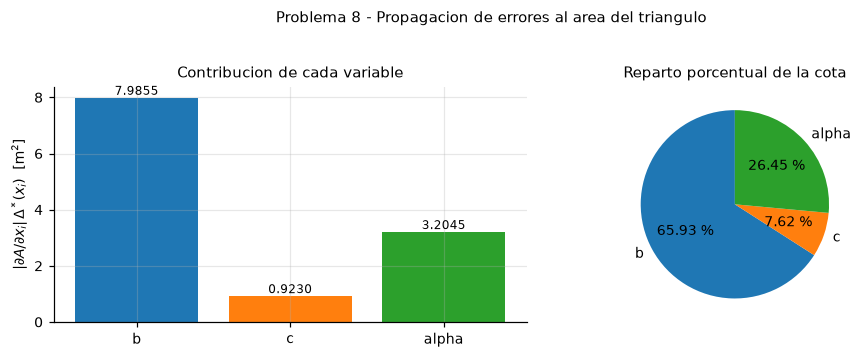

In [12]:
contrib = [
    ("b", abs(dAdb) * db),
    ("c", abs(dAdc) * dc),
    ("alpha", abs(dAdal) * dalpha_rad),
]
nombres = [c[0] for c in contrib]
montos = [c[1] for c in contrib]
tot = sum(montos)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.1))

axes[0].bar(nombres, montos, color=["tab:blue", "tab:orange", "tab:green"])
for i, v in enumerate(montos):
    axes[0].text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=8)
axes[0].set_ylabel(r"$|\partial A/\partial x_i|\,\Delta^*(x_i)$  [m$^2$]")
axes[0].set_title("Contribucion de cada variable")

porcentajes = [100 * v / tot for v in montos]
axes[1].pie(porcentajes, labels=nombres, autopct="%1.2f %%",
            colors=["tab:blue", "tab:orange", "tab:green"], startangle=90)
axes[1].set_title("Reparto porcentual de la cota")

fig.suptitle("Problema 8 - Propagacion de errores al area del triangulo", y=1.03, fontsize=10)
fig.tight_layout()
plt.show()

**Resultado.** El área nominal resulta $A = 9.7163 \times 10^{4}\ \text{m}^2$. Las contribuciones individuales a la cota son $7.9855\ \text{m}^2$ por $b$, $0.9230\ \text{m}^2$ por $c$ y $3.2045\ \text{m}^2$ por el ángulo, de modo que

$$\Delta^*(A) \approx 12.113\ \text{m}^2, \qquad \varepsilon^*(A) \approx 1.247 \times 10^{-4}.$$

El lado $b$ contribuye con cerca del $66\,\%$ de la cota total, lo que indica que la exactitud del resultado está dominada por la precisión con que se mide dicho lado. Con cotas diez veces menores en $b$ y $c$, el término angula se convertiría en el contribuyente dominante.

### Problema 9

**Enunciado.** Si las longitudes de los lados de un rectángulo tienen cotas de error relativo $\varepsilon^*(a) = 0.03$ y $\varepsilon^*(b) = 0.04$, determinar una cota de error en el cálculo del área.

**Formulación.** Para el producto $A = a \cdot b$, la cota de error relativo del resultado es la suma de las cotas relativas de los factores:

$$\varepsilon^*(A) = \varepsilon^*(a) + \varepsilon^*(b), \qquad \Delta^*(A) = A\,\varepsilon^*(A).$$

In [13]:
eps_a, eps_b = 0.03, 0.04

eps_A = eps_a + eps_b

print(f"Cotas relativas de los lados:  eps*(a) = {eps_a} ({eps_a * 100:.0f} %), eps*(b) = {eps_b} ({eps_b * 100:.0f} %)")
print(f"Cota relativa del area:        eps*(A) = eps*(a) + eps*(b) = {eps_A} ({eps_A * 100:.0f} %)")
print(f"Cota absoluta del area:        Delta*(A) = {eps_A} * a * b = 0.07 * a * b\n")

resumen9 = pd.DataFrame([
    ["a", eps_a, eps_a * 100],
    ["b", eps_b, eps_b * 100],
    ["A = a*b", eps_A, eps_A * 100],
], columns=["magnitud", "eps*", "eps* (%)"])
tabla(resumen9)

Cotas relativas de los lados:  eps*(a) = 0.03 (3 %), eps*(b) = 0.04 (4 %)
Cota relativa del area:        eps*(A) = eps*(a) + eps*(b) = 0.07 (7 %)
Cota absoluta del area:        Delta*(A) = 0.07 * a * b = 0.07 * a * b



,magnitud,eps*,eps* (%)
0,a,0.030000,3.000000
1,b,0.040000,4.000000
2,A = a*b,0.070000,7.000000


**Resultado.** La cota de error relativo del área es $\varepsilon^*(A) = 0.03 + 0.04 = 0.07$, es decir un $7\,\%$, y la cota de error absoluto queda expresada en función de las dimensiones como $\Delta^*(A) = 0.07\,a\,b$. En un producto la magnitud del error relativo no depende de los valores de los factores, sino exclusivamente de las cotas relativas de entrada.

### Problema 10

**Enunciado.** Tomando $x = \pi$ y $y = \sqrt{2}$ con cinco cifras significativas, determinar cuántas cifras significativas tiene la operación $\dfrac{\pi}{\sqrt{2}}$.

**Datos.** $x = \pi$, $y = \sqrt{2}$, ambas con $m = 5$ cifras significativas exactas.

**Formulación.** Para el cociente $f(x, y) = \dfrac{x}{y}$, la cota de error absoluto se propaga como

$$\Delta^*(f) = \left|\frac{\partial f}{\partial x}\right|\Delta^*(x) + \left|\frac{\partial f}{\partial y}\right|\Delta^*(y)
= \frac{1}{y}\Delta^*(x) + \frac{x}{y^2}\Delta^*(y),$$

con $\Delta^*(x) = \Delta^*(y) = 10^{k-m} = 10^{-4}$ en ambos casos. El número de cifras significativas del resultado se obtiene comparando $\Delta^*(f)$ con $10^{k_f - m_f}$.

In [14]:
x10 = math.pi
y10 = math.sqrt(2.0)
m10 = 5

x_ap = cifras_sig(x10, m10)
y_ap = cifras_sig(y10, m10)

kx, ky = orden_magnitud(x_ap), orden_magnitud(y_ap)
dx, dy = 10.0 ** (kx - m10), 10.0 ** (ky - m10)

f10 = x_ap / y_ap
kf = orden_magnitud(f10)

dfdx, dfdy = 1.0 / y_ap, x_ap / y_ap**2
df = propagacion_abs([dfdx, dfdy], [dx, dy])

print(f"x = pi       ~ {x_ap:.6f}  (k = {kx},  Delta*(x) = {dx:.1e})")
print(f"y = sqrt(2)  ~ {y_ap:.6f}  (k = {ky},  Delta*(y) = {dy:.1e})")
print(f"f = x/y      = {f10:.8f}  (k_f = {kf},  normalizada = {normalizada_str(f10)})\n")
print(f"Derivadas parciales:  |df/dx| = {dfdx:.6f}  |df/dy| = {dfdy:.6f}")
print(f"Cota de error absoluto  Delta*(f) = {df:.6e}\n")

print("Cifras significativas del resultado (Delta*(f) <= 10^(k_f - m_f)):")
filas10 = []
for mf in range(1, 8):
    cota = 10.0 ** (kf - mf)
    ok = df <= cota
    a_f = cifras_sig(f10, mf)
    print(f"  m_f = {mf}: 10^(k_f - m_f) = {cota:.3e} | cumple = {ok} | f redondeado = {a_f:.6f}")
    filas10.append([mf, cota, ok, a_f])

tabla(pd.DataFrame(filas10, columns=["m_f", "10^(k_f - m_f)", "cumple", "f (m_f cs)"]))

x = pi       ~ 3.141600  (k = 1,  Delta*(x) = 1.0e-04)
y = sqrt(2)  ~ 1.414200  (k = 1,  Delta*(y) = 1.0e-04)
f = x/y      = 2.22146797  (k_f = 1,  normalizada = 0.222147 x 10^1)

Derivadas parciales:  |df/dx| = 0.707114  |df/dy| = 1.570830
Cota de error absoluto  Delta*(f) = 2.277944e-04

Cifras significativas del resultado (Delta*(f) <= 10^(k_f - m_f)):
  m_f = 1: 10^(k_f - m_f) = 1.000e+00 | cumple = True | f redondeado = 2.000000
  m_f = 2: 10^(k_f - m_f) = 1.000e-01 | cumple = True | f redondeado = 2.200000
  m_f = 3: 10^(k_f - m_f) = 1.000e-02 | cumple = True | f redondeado = 2.220000
  m_f = 4: 10^(k_f - m_f) = 1.000e-03 | cumple = True | f redondeado = 2.221000
  m_f = 5: 10^(k_f - m_f) = 1.000e-04 | cumple = False | f redondeado = 2.221500
  m_f = 6: 10^(k_f - m_f) = 1.000e-05 | cumple = False | f redondeado = 2.221470
  m_f = 7: 10^(k_f - m_f) = 1.000e-06 | cumple = False | f redondeado = 2.221468


,m_f,10^(k_f - m_f),cumple,f (m_f cs)
0,1,1.000000,True,2.000000
1,2,0.100000,True,2.200000
2,3,0.010000,True,2.220000
3,4,0.001000,True,2.221000
4,5,0.000100,False,2.221500
5,6,0.000010,False,2.221470
6,7,0.000001,False,2.221468


**Resultado.** Las derivadas parciales evaluadas en el punto son $\left|\dfrac{\partial f}{\partial x}\right| = 7.0711 \times 10^{-1}$ y $\left|\dfrac{\partial f}{\partial y}\right| = 1.5708$, de modo que la cota de error absoluto del cociente es

$$\Delta^*(f) = 0.70711 \times 10^{-4} + 1.57083 \times 10^{-4} = 2.27794 \times 10^{-4}.$$

Comparando con el criterio $\Delta^*(f) \le 10^{k_f - m_f}$, con $k_f = 1$, se cumple para $m_f \ge 4$ y no para $m_f = 5$. La operación $\dfrac{\pi}{\sqrt{2}}$ tiene por tanto **$4$ cifras significativas exactas**, y el valor apropiado es $f = 2.2215$. Nótese que el cociente pierde una cifra significativa respecto de los datos de entrada, efecto atribuible al término $\left|\dfrac{\partial f}{\partial y}\right|$ del denominador, que triplica la sensibilidad respecto del numerador.

## 3. Método inverso - Enunciados 1 a 5

### Problema 1

**Enunciado.** **a)** Calcular el volumen de un paralelepípedo rectangular cuyas aristas miden $x = 0.35$ m, $y = 0.40$ m, $z = 0.45$ m, con una cota de error absoluto en el volumen $\Delta^*(V) \le 350\ \text{cm}^3$. **b)** ¿Con qué aproximación deberán medirse las aristas? Utilice la hipótesis que crea más conveniente.

**Formulación.** El volumen es $V = x\,y\,z$ y sus derivadas parciales son

$$\frac{\partial V}{\partial x} = y\,z, \qquad \frac{\partial V}{\partial y} = x\,z, \qquad \frac{\partial V}{\partial z} = x\,y.$$

Se adopta la **hipótesis de igualdad de efectos** (H3), que distribuye la tolerancia total por igual entre las contribuciones individuales de cada variable:

$$\left|\frac{\partial V}{\partial x}\right|\Delta^*(x) = \left|\frac{\partial V}{\partial y}\right|\Delta^*(y) = \left|\frac{\partial V}{\partial z}\right|\Delta^*(z) = \frac{\Delta^*(V)}{3}.$$

In [15]:
x1p, y1p, z1p = 0.35, 0.40, 0.45
delta_V = 350e-6  # m^3

V1 = x1p * y1p * z1p
parciales1 = [y1p * z1p, x1p * z1p, x1p * y1p]

efecto1, cotas1 = hipotesis3(parciales1, delta_V, 3)

print(f"Volumen nominal  V = {V1:.6f} m^3 = {V1 * 1e6:.1f} cm^3")
print(f"Tolerancia       Delta*(V) = {delta_V:.6e} m^3 = {delta_V * 1e6:.1f} cm^3")
print(f"Efecto individual = Delta*(V)/3 = {efecto1:.6e} m^3 = {efecto1 * 1e6:.3f} cm^3\n")

nombres = ["x", "y", "z"]
valores = [x1p, y1p, z1p]
filas1p = []
for nom, val, par, cot in zip(nombres, valores, parciales1, cotas1):
    eps = cot / abs(val)
    print(f"Variable {nom}: |dV/d{nom}| = {par:.6f} m^2 | Delta*({nom}) = {cot:.6e} m = {cot * 1000:.4f} mm"
          f" | eps*({nom}) = {eps:.3e} = {eps * 100:.4f} %")
    filas1p.append([nom, val, par, cot, cot * 1000, eps, eps * 100])

tabla(pd.DataFrame(filas1p, columns=["var", "valor", "|dV/dvar|", "Delta*", "Delta* (mm)", "eps*", "eps* (%)"]))

Volumen nominal  V = 0.063000 m^3 = 63000.0 cm^3
Tolerancia       Delta*(V) = 3.500000e-04 m^3 = 350.0 cm^3
Efecto individual = Delta*(V)/3 = 1.166667e-04 m^3 = 116.667 cm^3

Variable x: |dV/dx| = 0.180000 m^2 | Delta*(x) = 6.481481e-04 m = 0.6481 mm | eps*(x) = 1.852e-03 = 0.1852 %
Variable y: |dV/dy| = 0.157500 m^2 | Delta*(y) = 7.407407e-04 m = 0.7407 mm | eps*(y) = 1.852e-03 = 0.1852 %
Variable z: |dV/dz| = 0.140000 m^2 | Delta*(z) = 8.333333e-04 m = 0.8333 mm | eps*(z) = 1.852e-03 = 0.1852 %


,var,valor,|dV/dvar|,Delta*,Delta* (mm),eps*,eps* (%)
0,x,0.350000,0.180000,0.000648,0.648148,0.001852,0.185185
1,y,0.400000,0.157500,0.000741,0.740741,0.001852,0.185185
2,z,0.450000,0.140000,0.000833,0.833333,0.001852,0.185185


**Resultado.** **a)** El volumen nominal es $V = 0.063\ \text{m}^3 = 63\,000\ \text{cm}^3$.

**b)** La hipótesis de efectos iguales es la apropiada por tratarse de tres magnitudes geométricas homogéneas cuyas derivadas parciales tienen el mismo orden de magnitud. Las cotas resultantes son

$$\Delta^*(x) = 0.648\ \text{mm}, \qquad \Delta^*(y) = 0.741\ \text{mm}, \qquad \Delta^*(z) = 0.833\ \text{mm},$$

con una tolerancia relativa del $0.15\,\%$ en el volumen.

### Problema 2

**Enunciado.** Se desea determinar el área del paralelogramo con una cota de error absoluto $\Delta^*(A) \le 10^{-3}\ \text{cm}^2$. Datos: $b = 12.1$ cm, $h = 1.55$ cm, $\alpha = 32.5^\circ$. **a)** ¿Con cuántas cifras significativas deberán tomarse $b$, $h$ y $\alpha$? **b)** ¿Cuál es la hipótesis que correspondería utilizar? Justifique su respuesta.

**Formulación.** El área es $A = b\,h\,\operatorname{sen}(\alpha)$ con derivadas parciales

$$\frac{\partial A}{\partial b} = h\,\operatorname{sen}\alpha, \qquad
\frac{\partial A}{\partial h} = b\,\operatorname{sen}\alpha, \qquad
\frac{\partial A}{\partial \alpha} = b\,h\,\cos\alpha.$$

Las cotas se obtienen por efectos iguales (H3) y se convierten a cifras significativas mediante el criterio $\Delta^*(x) \le 10^{k-m}$.

In [16]:
b2, h2 = 12.1, 1.55
alpha2_deg = 32.5
alpha2_rad = math.radians(alpha2_deg)
delta_A = 1e-3  # cm^2

sen2, cos2 = math.sin(alpha2_rad), math.cos(alpha2_rad)
A2 = b2 * h2 * sen2
parciales2 = [h2 * sen2, b2 * sen2, b2 * h2 * cos2]

efecto2, cotas2 = hipotesis3(parciales2, delta_A, 3)

print(f"sen(alpha) = {sen2:.7f} | cos(alpha) = {cos2:.7f}")
print(f"Area nominal  A = {A2:.6f} cm^2")
print(f"Tolerancia   Delta*(A) = {delta_A:.1e} cm^2")
print(f"Efecto individual = {efecto2:.6e} cm^2\n")

nombres2 = ["b", "h", "alpha"]
valores2 = [b2, h2, alpha2_rad]
filas2p = []
for nom, val, par, cot in zip(nombres2, valores2, parciales2, cotas2):
    eps = cot / abs(val)
    k = orden_magnitud(val)
    m_min = None
    for m in range(1, 12):
        if cot <= 10.0 ** (k - m):
            m_min = m
            break
    print(f"Variable {nom:5s}: |dA/d{nom}| = {par:.6f} | Delta* = {cot:.6e} | eps* = {eps:.4e}"
          f" | k = {k} | m_min = {m_min}")
    filas2p.append([nom, val, par, cot, eps, k, m_min])

tabla(pd.DataFrame(filas2p, columns=["var", "valor", "|dA/dvar|", "Delta*", "eps*", "k", "m (min)"]))

print("\nCota del angulo expresada en segundos de arco:")
print(f"  Delta*(alpha) = {cotas2[2]:.6e} rad = {math.degrees(cotas2[2]) * 3600:.4f} ''")

sen(alpha) = 0.5372996 | cos(alpha) = 0.8433914
Area nominal  A = 10.077054 cm^2
Tolerancia   Delta*(A) = 1.0e-03 cm^2
Efecto individual = 3.333333e-04 cm^2

Variable b    : |dA/db| = 0.832814 | Delta* = 4.002492e-04 | eps* = 3.3078e-05 | k = 2 | m_min = 1
Variable h    : |dA/dh| = 6.501325 | Delta* = 5.127160e-05 | eps* = 3.3078e-05 | k = 1 | m_min = 1
Variable alpha: |dA/dalpha| = 15.817807 | Delta* = 2.107330e-05 | eps* = 3.7151e-05 | k = 0 | m_min = 1


,var,valor,|dA/dvar|,Delta*,eps*,k,m (min)
0,b,12.100000,0.832814,0.000400,0.000033,2,1
1,h,1.550000,6.501325,0.000051,0.000033,1,1
2,alpha,0.567232,15.817807,0.000021,0.000037,0,1



Cota del angulo expresada en segundos de arco:
  Delta*(alpha) = 2.107330e-05 rad = 4.3467 ''


**Resultado.** **b)** Corresponde utilizar la hipótesis de efectos iguales. Las tres variables representan magnitudes físicas distintas (dos longitudes y un ángulo) con sensibilidades muy dispares: $\left|\dfrac{\partial A}{\partial \alpha}\right| \approx 15.8$ frente a $\left|\dfrac{\partial A}{\partial b}\right| \approx 0.83$. Suponer cotas de error absoluto iguales no tendría significado físico al mezclar unidades incompatibles.

**a)** Las cotas resultantes son $\Delta^*(b) = 4.00 \times 10^{-4}$ cm, $\Delta^*(h) = 5.13 \times 10^{-5}$ cm y $\Delta^*(\alpha) = 2.11 \times 10^{-5}$ rad $\approx 4.35''$, lo que exige

$$m_b = 6, \qquad m_h = 6, \qquad m_\alpha = 5 \ \text{cifras significativas}.$$

### Problema 3

**Enunciado.** ¿Con qué precisión deben medirse las variables $x$ e $y$ para que el cálculo de la función $z = x\,y - \operatorname{sen}(x)\,\operatorname{tg}(y)$ tenga una cota de error $\Delta^*(z) \le 0.1$? Datos: $x \approx 5.7$, $y \approx 1.1$. **a)** Suponer cotas de errores absolutos iguales. **b)** Suponer cotas de errores relativos iguales. **c)** Suponer efectos iguales.

**Formulación.** Las derivadas parciales son

$$\frac{\partial z}{\partial x} = y - \cos(x)\,\operatorname{tg}(y), \qquad
\frac{\partial z}{\partial y} = x - \frac{\operatorname{sen}(x)}{\cos^2(y)}.$$

Se resuelve el problema bajo las tres hipótesis y se compara la precisión exigida a cada variable.

In [17]:
x3, y3 = 5.7, 1.1
delta_z = 0.1

sen3, cos3 = math.sin(x3), math.cos(x3)
tg3, cos_y3 = math.tan(y3), math.cos(y3)

z3 = x3 * y3 - sen3 * tg3
dzdx = y3 - cos3 * tg3
dzdy = x3 - sen3 / cos_y3**2
parciales3 = [dzdx, dzdy]

print(f"sen(x) = {sen3:.7f} | cos(x) = {cos3:.7f} | tg(y) = {tg3:.7f} | cos(y) = {cos_y3:.7f}")
print(f"Valor nominal  z = {z3:.6f}")
print(f"Derivadas parciales:  dz/dx = {dzdx:.6f} | dz/dy = {dzdy:.6f}\n")

filas3p = []

dgen1, cotas_h1 = hipotesis1(parciales3, delta_z)
print("--- a) H1: cotas de error absoluto iguales")
print(f"  Delta*_gen = {dgen1:.6e}")
for nom, val, cot in zip(["x", "y"], [x3, y3], cotas_h1):
    eps = cot / abs(val)
    print(f"  Delta*({nom}) = {cot:.6e} | eps*({nom}) = {eps:.6e} = {eps * 100:.4f} %")
    filas3p.append(["H1", nom, cot, eps, eps * 100])

egen2, cotas_h2 = hipotesis2(parciales3, [x3, y3], delta_z)
print("\n--- b) H2: cotas de error relativo iguales")
print(f"  eps*_gen = {egen2:.6e} = {egen2 * 100:.4f} %")
for nom, val, cot in zip(["x", "y"], [x3, y3], cotas_h2):
    print(f"  eps*({nom}) = {egen2:.6e} | Delta*({nom}) = {cot:.6e}")
    filas3p.append(["H2", nom, cot, egen2, egen2 * 100])

efecto3, cotas_h3 = hipotesis3(parciales3, delta_z, 2)
print("\n--- c) H3: efectos iguales")
print(f"  Efecto individual = {efecto3:.6e}")
for nom, val, cot in zip(["x", "y"], [x3, y3], cotas_h3):
    eps = cot / abs(val)
    print(f"  Delta*({nom}) = {cot:.6e} | eps*({nom}) = {eps:.6e} = {eps * 100:.4f} %")
    filas3p.append(["H3", nom, cot, eps, eps * 100])

tabla(pd.DataFrame(filas3p, columns=["hipotesis", "var", "Delta*", "eps*", "eps* (%)"]))

sen(x) = -0.5506855 | cos(x) = 0.8347128 | tg(y) = 1.9647597 | cos(y) = 0.4535961
Valor nominal  z = 7.351965
Derivadas parciales:  dz/dx = -0.540010 | dz/dy = 8.376486

--- a) H1: cotas de error absoluto iguales
  Delta*_gen = 1.121517e-02
  Delta*(x) = 1.121517e-02 | eps*(x) = 1.967573e-03 = 0.1968 %
  Delta*(y) = 1.121517e-02 | eps*(y) = 1.019561e-02 = 1.0196 %

--- b) H2: cotas de error relativo iguales
  eps*_gen = 8.135246e-03 = 0.8135 %
  eps*(x) = 8.135246e-03 | Delta*(x) = 4.637090e-02
  eps*(y) = 8.135246e-03 | Delta*(y) = 8.948770e-03

--- c) H3: efectos iguales
  Efecto individual = 5.000000e-02
  Delta*(x) = 9.259088e-02 | eps*(x) = 1.624401e-02 = 1.6244 %
  Delta*(y) = 5.969090e-03 | eps*(y) = 5.426445e-03 = 0.5426 %


,hipotesis,var,Delta*,eps*,eps* (%)
0,H1,x,0.011215,0.001968,0.196757
1,H1,y,0.011215,0.010196,1.019561
2,H2,x,0.046371,0.008135,0.813525
3,H2,y,0.008949,0.008135,0.813525
4,H3,x,0.092591,0.016244,1.624401
5,H3,y,0.005969,0.005426,0.542645


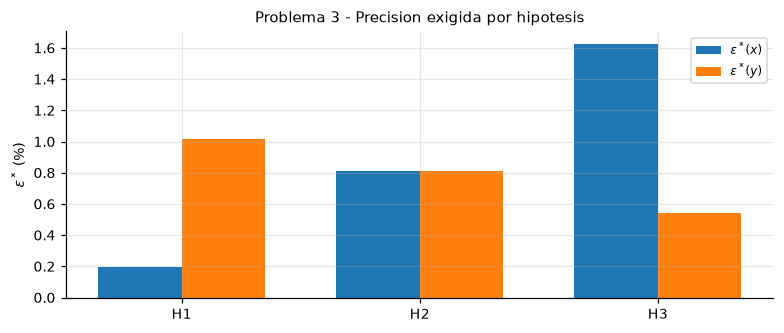

In [18]:
fig, ax = plt.subplots(figsize=(7.2, 3.1))

hip_labels = ["H1", "H2", "H3"]
x_vals = np.arange(len(hip_labels))
w = 0.35

eps_x = [r[4] for r in filas3p if r[1] == "x"]
eps_y = [r[4] for r in filas3p if r[1] == "y"]

ax.bar(x_vals - w / 2, eps_x, w, label=r"$\varepsilon^*(x)$", color="tab:blue")
ax.bar(x_vals + w / 2, eps_y, w, label=r"$\varepsilon^*(y)$", color="tab:orange")
ax.set_xticks(x_vals)
ax.set_xticklabels(hip_labels)
ax.set_ylabel(r"$\varepsilon^*$ (%)")
ax.set_title("Problema 3 - Precision exigida por hipotesis")
ax.legend(loc="best")
fig.tight_layout()
plt.show()

**Resultado.** La hipótesis seleccionada modifica de forma sustancial la exigencia impuesta a cada variable:

| Hipótesis | $\Delta^*(x)$ | $\Delta^*(y)$ | $\varepsilon^*(x)$ | $\varepsilon^*(y)$ |
|---|---|---|---|---|
| H1 - absolutas iguales | $1.122 \times 10^{-2}$ | $1.122 \times 10^{-2}$ | $0.197\,\%$ | $1.020\,\%$ |
| H2 - relativas iguales | $4.637 \times 10^{-2}$ | $8.949 \times 10^{-3}$ | $0.814\,\%$ | $0.814\,\%$ |
| H3 - efectos iguales | $9.259 \times 10^{-2}$ | $5.969 \times 10^{-3}$ | $1.624\,\%$ | $0.543\,\%$ |

La hipótesis H2 resulta la más equilibrada al imponer una única precisión relativa, mientras que H3 alivia la exigencia sobre $x$ a costa de restringir severamente $y$, en razón de la mayor sensibilidad de $\dfrac{\partial z}{\partial y}$.

### Problema 4

**Enunciado.** Dada la función $f = -y\,t^2 + 2t$, con $\Delta^*(f) \le 0.02$, $t \approx 2.4$, $y \approx 0.5$. **a)** Determinar por la hipótesis de efectos iguales con qué aproximación deben tomarse $t$ e $y$. **b)** ¿En qué intervalos se puede decir que se encuentran los valores exactos de $t$ y de $y$?

**Formulación.** Las derivadas parciales son

$$\frac{\partial f}{\partial t} = -2\,y\,t + 2, \qquad \frac{\partial f}{\partial y} = -t^2,$$

y la hipótesis de efectos iguales impone

$$\left|\frac{\partial f}{\partial t}\right|\Delta^*(t) = \left|\frac{\partial f}{\partial y}\right|\Delta^*(y) = \frac{\Delta^*(f)}{2}.$$

In [19]:
t4, y4 = 2.4, 0.5
delta_f = 0.02

f4 = -y4 * t4**2 + 2 * t4
dfdt = -2 * y4 * t4 + 2
dfdy = -t4**2
parciales4 = [dfdt, dfdy]

efecto4, cotas4 = hipotesis3(parciales4, delta_f, 2)

print(f"Valor nominal  f = {f4:.6f}")
print(f"Derivadas parciales:  df/dt = {dfdt:.6f} | df/dy = {dfdy:.6f}")
print(f"Efecto individual = Delta*(f)/2 = {efecto4:.6f}\n")

for nom, val, cot in zip(["t", "y"], [t4, y4], cotas4):
    eps = cot / abs(val)
    li, ls = val - cot, val + cot
    print(f"Variable {nom}: Delta*({nom}) = {cot:.7f} | eps*({nom}) = {eps:.6e} = {eps * 100:.4f} %")
    print(f"          Intervalo exacto I({nom}) = [{li:.6f}, {ls:.6f}]\n")

tabla(pd.DataFrame([
    ["t", t4, cotas4[0], cotas4[0] / t4, t4 - cotas4[0], t4 + cotas4[0]],
    ["y", y4, cotas4[1], cotas4[1] / y4, y4 - cotas4[1], y4 + cotas4[1]],
], columns=["var", "valor", "Delta*", "eps*", "I(inf)", "I(sup)"]))

Valor nominal  f = 1.920000
Derivadas parciales:  df/dt = -0.400000 | df/dy = -5.760000
Efecto individual = Delta*(f)/2 = 0.010000

Variable t: Delta*(t) = 0.0250000 | eps*(t) = 1.041667e-02 = 1.0417 %
          Intervalo exacto I(t) = [2.375000, 2.425000]

Variable y: Delta*(y) = 0.0017361 | eps*(y) = 3.472222e-03 = 0.3472 %
          Intervalo exacto I(y) = [0.498264, 0.501736]



,var,valor,Delta*,eps*,I(inf),I(sup)
0,t,2.400000,0.025000,0.010417,2.375000,2.425000
1,y,0.500000,0.001736,0.003472,0.498264,0.501736


**Resultado.** **a)** Las cotas de aproximación exigidas son $\Delta^*(t) = 0.025$ y $\Delta^*(y) = 1.7361 \times 10^{-3}$.

**b)** Los intervalos que contienen a los valores exactos son

$$I(t) = [2.375,\ 2.425], \qquad I(y) = [0.498264,\ 0.501736].$$

La variable $t$ admite una tolerancia quince veces mayor que $y$, resultado directo de la relación $\dfrac{|\partial f/\partial y|}{|\partial f/\partial t|} = 14.4$ entre las sensibilidades parciales.

### Problema 5

**Enunciado.** Dada la función $z = \cos(a)\,\ln(b)$, con $a = 38^\circ 47' 33''$ y $b = 2.1523$, determinar con qué precisión deben medirse $a$ y $b$ para que $z$ tenga tres cifras significativas. ¿Corresponde a un problema de método directo o de método inverso? Justifique su respuesta.

**Formulación.** El problema es de **método inverso**: se fija el nivel de exactitud de la salida ($m_z = 3$) y se determinan las cotas de las entradas. La cota de la función es $\Delta^*(z) \le 10^{k_z - m_z}$. Las derivadas parciales son

$$\frac{\partial z}{\partial a} = -\operatorname{sen}(a)\,\ln(b), \qquad
\frac{\partial z}{\partial b} = \frac{\cos(a)}{b},$$

con $a$ expresada en radianes.

In [20]:
a_deg = 38 + 47 / 60 + 33 / 3600
a_rad = math.radians(a_deg)
b5 = 2.1523
m_z = 3

z5 = math.cos(a_rad) * math.log(b5)
kz = orden_magnitud(z5)
delta_z5 = 10.0 ** (kz - m_z)

dzda = -math.sin(a_rad) * math.log(b5)
dzdb = math.cos(a_rad) / b5
parciales5 = [dzda, dzdb]

print(f"a = {a_deg:.6f} grados = {a_rad:.6f} rad")
print(f"b = {b5}")
print(f"z = cos(a) ln(b) = {z5:.8f}  (k_z = {kz}, normalizada = {normalizada_str(z5)})")
print(f"Con m_z = {m_z} cs:  Delta*(z) <= 10^({kz} - {m_z}) = {delta_z5:.1e}\n")
print(f"Derivadas parciales:  dz/da = {dzda:.6f} rad^-1 | dz/db = {dzdb:.6f}")

efecto5, cotas5 = hipotesis3(parciales5, delta_z5, 2)
print(f"Efecto individual = {efecto5:.6e}\n")

a_cota, b_cota = cotas5
print(f"Para a: Delta*(a) = {a_cota:.7f} rad")
print(f"        en grados  = {math.degrees(a_cota):.6f} grados")
print(f"        en minutos = {math.degrees(a_cota) * 60:.3f} '")
print(f"        en segundos= {math.degrees(a_cota) * 3600:.2f} ''")
print(f"        precision  eps*(a) = {a_cota / a_rad:.6e} = {a_cota / a_rad * 100:.4f} %\n")
print(f"Para b: Delta*(b) = {b_cota:.7f}")
print(f"        precision  eps*(b) = {b_cota / b5:.6e} = {b_cota / b5 * 100:.4f} %")

# Verificacion por H2
egen5, cotas5_h2 = hipotesis2(parciales5, [a_rad, b5], delta_z5)
print(f"\nVerificacion por H2 (cotas relativas iguales): eps*_gen = {egen5:.6e} = {egen5 * 100:.4f} %")

a = 38.792500 grados = 0.677057 rad
b = 2.1523
z = cos(a) ln(b) = 0.59745428  (k_z = 0, normalizada = 0.597454 x 10^0)
Con m_z = 3 cs:  Delta*(z) <= 10^(0 - 3) = 1.0e-03

Derivadas parciales:  dz/da = -0.480237 rad^-1 | dz/db = 0.362134
Efecto individual = 5.000000e-04

Para a: Delta*(a) = 0.0010412 rad
        en grados  = 0.059654 grados
        en minutos = 3.579 '
        en segundos= 214.75 ''
        precision  eps*(a) = 1.537763e-03 = 0.1538 %

Para b: Delta*(b) = 0.0013807
        precision  eps*(b) = 6.415027e-04 = 0.0642 %

Verificacion por H2 (cotas relativas iguales): eps*_gen = 9.053316e-04 = 0.0905 %


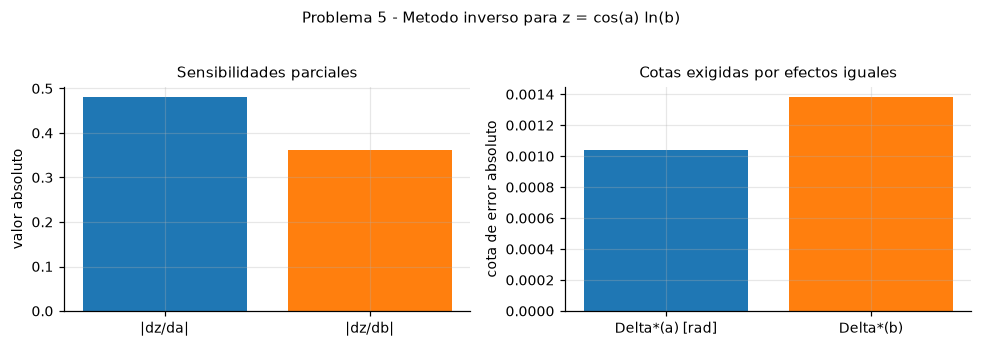

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.0))

axes[0].bar(["|dz/da|", "|dz/db|"], [abs(dzda), abs(dzdb)], color=["tab:blue", "tab:orange"])
axes[0].set_ylabel("valor absoluto")
axes[0].set_title("Sensibilidades parciales")

axes[1].bar(["Delta*(a) [rad]", "Delta*(b)"], [a_cota, b_cota], color=["tab:blue", "tab:orange"])
axes[1].set_ylabel("cota de error absoluto")
axes[1].set_title("Cotas exigidas por efectos iguales")

fig.suptitle("Problema 5 - Metodo inverso para z = cos(a) ln(b)", y=1.03, fontsize=10)
fig.tight_layout()
plt.show()

**Resultado.** El problema corresponde al **método inverso**: la restricción se impone sobre la exactitud de la salida ($z$ con tres cifras significativas) y se determinan las cotas previas de las entradas. La función vale $z = 5.9746 \times 10^{-1}$, con $k_z = 0$, de modo que $\Delta^*(z) \le 10^{-3}$.

Aplicando efectos iguales, las precisiones exigidas son

$$\Delta^*(a) = 1.0412 \times 10^{-3}\ \text{rad} \approx 3'35'', \qquad \varepsilon^*(a) = 1.538 \times 10^{-3},$$

$$\Delta^*(b) = 1.3807 \times 10^{-3}, \qquad \varepsilon^*(b) = 6.415 \times 10^{-4}.$$

El ángulo $a$ admite una tolerancia relativa más laxa que $b$, en razón de la mayor sensibilidad de la derivada parcial respecto de $a$.

## 4. Cuadro resumen de resultados

El cuadro siguiente consolida las cotas y precisiones obtenidas a lo largo de los quince enunciados.

In [22]:
resumen = pd.DataFrame([
    ["Directo", "1", "Reparto de 100/3", "m = 6 cs", "Delta* = 3.333e-05 USD", "eps* = 1.0e-06"],
    ["Directo", "1", "Reparto de 100/3", "m = 2 cs", "Delta* = 3.333e-01 USD", "eps* = 1.0e-02"],
    ["Directo", "2", "Velocidad de la luz", "medida historica", "Delta* = 1776 km/s", "eps* = 5.924e-03"],
    ["Directo", "3", "Aproximaciones a pi", "5 cs", "Delta* ~ 7.35e-06", "eps* ~ 2.34e-06"],
    ["Directo", "4", "Redondeo a 3 cs", "defecto/exceso/prox.", "Delta* < 1e-02", "-"],
    ["Directo", "5", "Cotas y cifras de pi", "Delta* < 1e-06", "m_min = 7 cs", "-"],
    ["Directo", "6", "Resta x1 - x2", "propagacion", "Delta* = 0.05", "eps* = 5.618e-02"],
    ["Directo", "7", "Resistencia R = V/I", "ley de Ohm", "Delta* = 1.65 ohm", "eps* = 3.0e-02"],
    ["Directo", "8", "Area del triangulo", "propagacion", "Delta* = 12.113 m^2", "eps* = 1.247e-04"],
    ["Directo", "9", "Area del rectangulo", "producto", "Delta* = 0.07 a b", "eps* = 7.0e-02"],
    ["Directo", "10", "Cociente pi/sqrt(2)", "5 cs entrada", "Delta* = 2.278e-04", "m_f = 4 cs"],
    ["Inverso", "1", "Paralelepipedo V=xyz", "H3", "Delta*(x,y,z) ~ 0.65-0.83 mm", "eps* ~ 0.15 %"],
    ["Inverso", "2", "Paralelogramo", "H3", "Delta*(alpha) ~ 4.35''", "m = 6, 6, 5 cs"],
    ["Inverso", "3", "z = xy - sen x tg y", "H1 / H2 / H3", "Delta*_gen = 1.122e-02", "eps* 0.197 - 1.624 %"],
    ["Inverso", "4", "f = -y t^2 + 2t", "H3", "Delta*(t) = 0.025", "Delta*(y) = 1.736e-03"],
    ["Inverso", "5", "z = cos(a) ln(b)", "H3", "Delta*(a) = 3'35''", "eps*(b) = 6.415e-04"],
], columns=["metodo", "problema", "objeto", "hipotesis / regla", "cota de error", "precision"])

display(resumen)

,metodo,problema,objeto,hipotesis / regla,cota de error,precision
0,Directo,1,Reparto de 100/3,m = 6 cs,Delta* = 3.333e-05 USD,eps* = 1.0e-06
1,Directo,1,Reparto de 100/3,m = 2 cs,Delta* = 3.333e-01 USD,eps* = 1.0e-02
2,Directo,2,Velocidad de la luz,medida historica,Delta* = 1776 km/s,eps* = 5.924e-03
3,Directo,3,Aproximaciones a pi,5 cs,Delta* ~ 7.35e-06,eps* ~ 2.34e-06
4,Directo,4,Redondeo a 3 cs,defecto/exceso/prox.,Delta* < 1e-02,-
5,Directo,5,Cotas y cifras de pi,Delta* < 1e-06,m_min = 7 cs,-
6,Directo,6,Resta x1 - x2,propagacion,Delta* = 0.05,eps* = 5.618e-02
7,Directo,7,Resistencia R = V/I,ley de Ohm,Delta* = 1.65 ohm,eps* = 3.0e-02
8,Directo,8,Area del triangulo,propagacion,Delta* = 12.113 m^2,eps* = 1.247e-04
9,Directo,9,Area del rectangulo,producto,Delta* = 0.07 a b,eps* = 7.0e-02


**Comentario final.** El método directo cuantifica la degradación de la exactitud al propagar las cotas de las entradas hasta el resultado, y pone de manifiesto cómo la sensibilidad de cada variable, medida por el módulo de su derivada parcial, condiciona la cota final. El método invierte ese razonamiento: fijada la tolerancia de salida, distribuye la exigencia entre las entradas mediante una hipótesis que debe justificarse según la naturaleza física de cada variable. En ambos enfoques, la selección de la hipótesis de propagación determina el resultado cuantitativo.